In [25]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# Leo la imagen 
img = cv2.imread('../calib/coplanar/Im_R_1.png')

# La paso a escala de grises
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Deteccion automática de esquinas
prettyCheck, corners = cv2.findChessboardCorners(gray, (11, 7), None)
print(f'found corners: {prettyCheck} \ncorners:\n {corners[0:5]}')


found corners: True 
corners:
 [[372.62646  104.17367 ]
 [413.56818  105.15602 ]
 [453.98776  105.766396]
 [494.5458   106.75583 ]
 [534.89453  107.47043 ]]


Text(0.5, 1.0, 'Esquinas detectadas - Imagen 1')

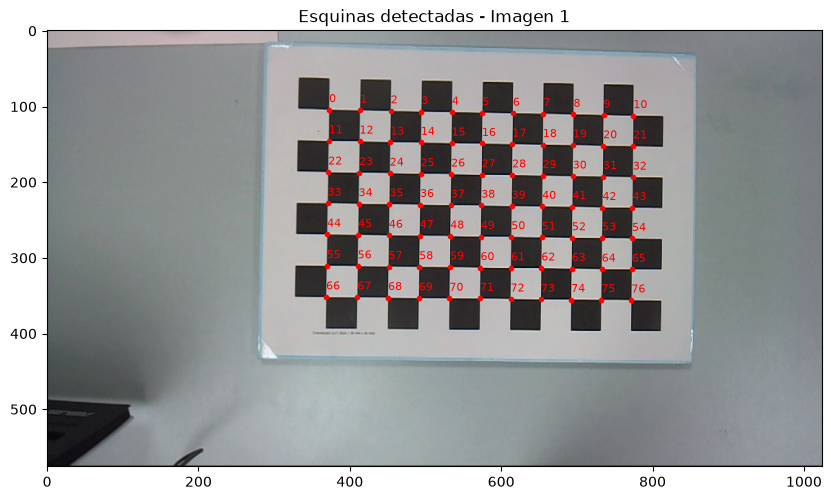

In [ ]:
# Verifico que los puntos hayan sido correctamente detectados

# corners (77,2,1) -> aplanar a (77,2)
pts = corners.reshape(-1, 2)

plt.figure(figsize=(10, 8))
plt.imshow(img)
plt.plot(pts[:, 0], pts[:, 1], 'r.', markersize=6)

for k in range(len(pts)):
    plt.text(pts[k, 0], pts[k, 1] - 10, str(k), color='red', fontsize=8)

plt.title('Esquinas detectadas - Imagen 1')


In [ ]:
# Detecto esquinas en las 10 imágenes
corners_result = []
for i in range(1, 11):
    # Leo la imagen
    img = cv2.imread(f'../calib/coplanar/Im_R_{i}.png')
    
    # La paso a escala de grises
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Deteccion automática de esquinas
    prettyCheck, corners = cv2.findChessboardCorners(gray, (11, 7), None)

    # corners (77,1,2) -> aplanar a (77,2)
    pts = corners.reshape(-1, 2)
    
    if prettyCheck == True:
        corners_result.append(pts)
        print(f'Imagen {i} OK')
    else:
        print(f'No se detectaron esquinas en la imagen {i}')
            

Imagen 1 OK
Imagen 2 OK
Imagen 3 OK
Imagen 4 OK
Imagen 5 OK
Imagen 6 OK
Imagen 7 OK
Imagen 8 OK
Imagen 9 OK
Imagen 10 OK


In [27]:
# Creo el archivo con las esquinas identificadas

# Aplano cada lista de esquinas a un array de 2D
filas = []
for corner in corners_result:
    fila = corner.reshape(1, -1)  # paso de (77,2) a (1,154)
    filas.append(fila)

# fila -> 10 arrays de (1,154) -> concateno a un único array de (10,154)
data = np.vstack(filas)

np.savetxt('../calib/coplanar/detected_corners.txt', data, fmt='%.2f')